# DATA 620 Final Project

## Provider Connections in the AI-Chip and Memory Supply Chain

**Research question:** Which companies and countries are most connected to five AI-chip and memory-related inputs, and which of those inputs have the fewest listed providers?

This project uses the September 2026 release of Georgetown University's Emerging Technology Observatory Semiconductor Supply Chain Dataset. I focus on discrete GPUs, AI ASICs, memory-chip design, memory-testing tools, and fabrication tools for advanced packaging.

The result describes the relationships listed in this dataset. It does not prove that a current shortage exists, measure physical production locations, or predict future supply problems.

## 1. Setup

This section loads common Python packages and defines relative project paths. The random seed makes the network layout repeatable.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
from networkx.algorithms import bipartite
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 620
PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent

RAW = PROJECT / "data" / "raw"
DERIVED = PROJECT / "data" / "derived"
OUTPUTS = PROJECT / "outputs"
DERIVED.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NetworkX:", nx.__version__)

Python: 3.14.6
pandas: 3.0.6
NetworkX: 3.7


## 2. Load and audit the source tables

The publisher supplies five CSV tables. I check their sizes, duplicate rows, and key relationships before selecting the project subset. Missing cells are expected in some optional fields, so I do not delete entire rows simply because one field is blank.

In [2]:
inputs = pd.read_csv(RAW / "inputs.csv")
providers_raw = pd.read_csv(RAW / "providers.csv")
provision = pd.read_csv(RAW / "provision.csv")
sequence = pd.read_csv(RAW / "sequence.csv")
stages = pd.read_csv(RAW / "stages.csv")

tables = {
    "inputs": inputs,
    "providers": providers_raw,
    "provision": provision,
    "sequence": sequence,
    "stages": stages,
}

table_audit = pd.DataFrame([
    {
        "table": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "duplicate_rows": int(frame.duplicated().sum()),
        "missing_cells": int(frame.isna().sum().sum()),
    }
    for name, frame in tables.items()
])

providers = providers_raw.drop_duplicates("provider_id", keep="first").copy()
valid_provided_ids = set(inputs["input_id"]).union(stages["stage_id"])

integrity = pd.DataFrame({
    "check": [
        "Unique input IDs",
        "Unique provider IDs",
        "Provision rows",
        "Provision provider IDs not found",
        "Provision input/stage IDs not found",
        "Sequence source IDs not found",
    ],
    "result": [
        inputs["input_id"].nunique(),
        providers["provider_id"].nunique(),
        len(provision),
        int((~provision["provider_id"].isin(providers["provider_id"])).sum()),
        int((~provision["provided_id"].isin(valid_provided_ids)).sum()),
        int((~sequence["input_id"].isin(inputs["input_id"])).sum()),
    ],
})

display(table_audit)
display(integrity)
table_audit.to_csv(OUTPUTS / "source_table_audit.csv", index=False)
integrity.to_csv(OUTPUTS / "referential_integrity_checks.csv", index=False)

,table,rows,columns,duplicate_rows,missing_cells
0,inputs,126,10,0,424
1,providers,403,5,0,352
2,provision,1300,7,0,373
3,sequence,139,6,0,278
4,stages,3,6,0,1


,check,result
0,Unique input IDs,126
1,Unique provider IDs,396
2,Provision rows,1300
3,Provision provider IDs not found,0
4,Provision input/stage IDs not found,0
5,Sequence source IDs not found,0


## 3. Select five understandable AI-chip and memory inputs

The full dataset contains 126 inputs and 1,300 provider-input relationships. I use five inputs that are directly connected to AI hardware and memory. I remove the aggregate placeholders `Various companies` and `Various countries` because they are not identifiable providers and would distort provider centrality.

In [3]:
focus_inputs = [
    "Discrete GPUs",
    "AI ASICs",
    "Memory chip design",
    "Memory test tools",
    "Fabrication tools (for advanced packaging)",
]

focus_raw = (
    provision.loc[provision["provided_name"].isin(focus_inputs)]
    .merge(
        providers[["provider_id", "provider_type", "country"]],
        on="provider_id",
        how="left",
        validate="many_to_one",
    )
)

aggregate_names = {"Various companies", "Various countries"}
focus = focus_raw.loc[~focus_raw["provider_name"].isin(aggregate_names)].copy()

country_names = {
    "USA": "United States", "CHN": "China", "JPN": "Japan", "KOR": "South Korea",
    "GBR": "United Kingdom", "TWN": "Taiwan", "AUT": "Austria", "CHE": "Switzerland",
    "DEU": "Germany", "FRA": "France", "ISR": "Israel", "NLD": "Netherlands",
    "SGP": "Singapore",
}
focus["provider_label"] = focus["provider_name"].replace(country_names)

focus_summary = (
    focus.groupby(["provided_name", "provider_type"])["provider_id"]
    .nunique()
    .unstack(fill_value=0)
    .rename(columns={"country": "countries", "organization": "organizations"})
    .reindex(focus_inputs)
)
focus_summary["total_listed_providers"] = focus_summary.sum(axis=1)

selection_audit = pd.DataFrame({
    "check": [
        "Focus relationships before exclusions",
        "Aggregate placeholder rows excluded",
        "Focus relationships analyzed",
        "Unique focus providers",
        "Focus inputs",
        "Missing provider types after join",
    ],
    "result": [
        len(focus_raw), len(focus_raw) - len(focus), len(focus),
        focus["provider_id"].nunique(), focus["provided_id"].nunique(),
        int(focus["provider_type"].isna().sum()),
    ],
})

display(selection_audit)
display(focus_summary)
focus.to_csv(DERIVED / "ai_chip_memory_focus_relationships.csv", index=False)
focus_summary.to_csv(OUTPUTS / "providers_by_focus_input.csv")

,check,result
0,Focus relationships before exclusions,61
1,Aggregate placeholder rows excluded,5
2,Focus relationships analyzed,56
3,Unique focus providers,43
4,Focus inputs,5
5,Missing provider types after join,0


provider_type,countries,organizations,total_listed_providers
provided_name,,,
Discrete GPUs,2,3,5
AI ASICs,3,8,11
Memory chip design,5,0,5
Memory test tools,3,5,8
Fabrication tools (for advanced packaging),13,14,27


## 4. Compare provider counts by input

This stacked bar chart separates countries from organizations. The count measures how many distinct providers are listed for each input after removing aggregate placeholders. Fewer listed providers can suggest a narrower provider base, but it does not prove that a shortage exists.

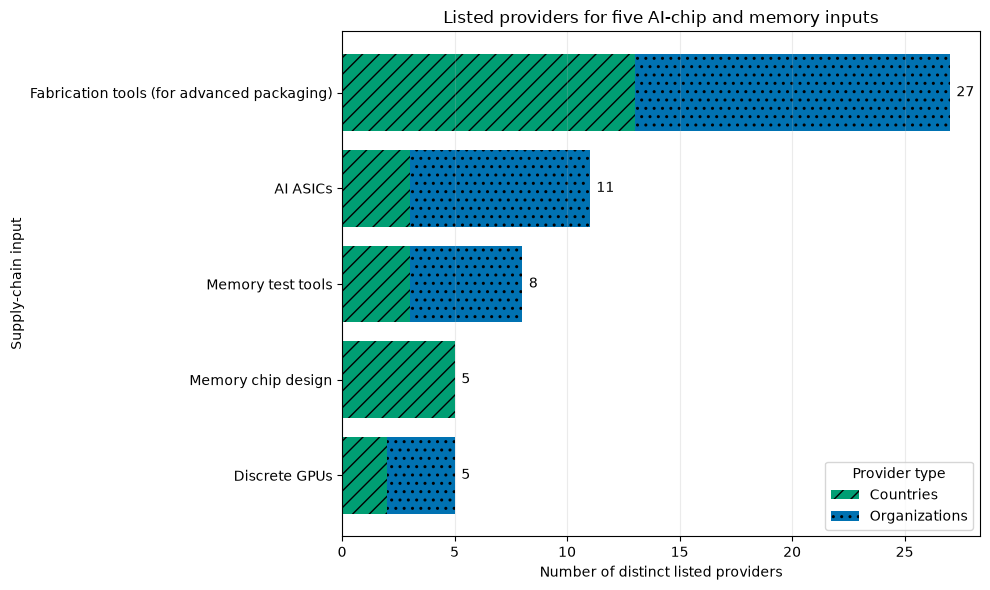

In [4]:
plot_counts = focus_summary.sort_values("total_listed_providers")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    plot_counts.index,
    plot_counts["countries"],
    color="#009E73",
    hatch="//",
    label="Countries",
)
ax.barh(
    plot_counts.index,
    plot_counts["organizations"],
    left=plot_counts["countries"],
    color="#0072B2",
    hatch="..",
    label="Organizations",
)

for index, total in enumerate(plot_counts["total_listed_providers"]):
    ax.text(total + 0.3, index, str(int(total)), va="center", fontsize=10)

ax.set_title("Listed providers for five AI-chip and memory inputs")
ax.set_xlabel("Number of distinct listed providers")
ax.set_ylabel("Supply-chain input")
ax.legend(title="Provider type")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUTS / "providers_by_focus_input.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Build the bipartite provider-input network

A bipartite network has two different node sets. Here, one set contains providers and the other contains chip inputs. An edge means that the dataset lists a company or country as a provider of that input. Degree counts how many edges touch a node.

In [5]:
graph = nx.Graph()

for row in focus.itertuples(index=False):
    provider_node = f"provider:{row.provider_id}"
    input_node = f"input:{row.provided_id}"

    graph.add_node(
        provider_node,
        label=row.provider_label,
        raw_label=row.provider_name,
        node_type=row.provider_type,
        bipartite=0,
    )
    graph.add_node(
        input_node,
        label=row.provided_name,
        node_type="input",
        bipartite=1,
    )
    graph.add_edge(
        provider_node,
        input_node,
        share_provided=row.share_provided,
        year=row.year,
    )

provider_nodes = [n for n, d in graph.nodes(data=True) if d["node_type"] != "input"]
input_nodes = [n for n, d in graph.nodes(data=True) if d["node_type"] == "input"]
betweenness = nx.betweenness_centrality(graph)

provider_metrics = pd.DataFrame([
    {
        "provider": graph.nodes[node]["label"],
        "provider_type": graph.nodes[node]["node_type"],
        "focus_input_degree": graph.degree(node),
        "betweenness_centrality": betweenness[node],
    }
    for node in provider_nodes
]).sort_values(
    ["focus_input_degree", "betweenness_centrality", "provider"],
    ascending=[False, False, True],
)

input_metrics = pd.DataFrame([
    {
        "input": graph.nodes[node]["label"],
        "listed_provider_degree": graph.degree(node),
        "betweenness_centrality": betweenness[node],
    }
    for node in input_nodes
]).sort_values("listed_provider_degree")

network_checks = pd.DataFrame({
    "check": ["Nodes", "Provider nodes", "Input nodes", "Edges", "Connected components", "Bipartite density"],
    "result": [
        graph.number_of_nodes(), len(provider_nodes), len(input_nodes), graph.number_of_edges(),
        nx.number_connected_components(graph), round(bipartite.density(graph, provider_nodes), 3),
    ],
})

display(network_checks)
display(provider_metrics.head(12).round(3))
display(input_metrics.round(3))

provider_metrics.to_csv(OUTPUTS / "provider_network_metrics.csv", index=False)
input_metrics.to_csv(OUTPUTS / "input_network_metrics.csv", index=False)
network_checks.to_csv(OUTPUTS / "network_checks.csv", index=False)

,check,result
0,Nodes,48.00
1,Provider nodes,43.00
2,Input nodes,5.00
3,Edges,56.00
4,Connected components,1.00
5,Bipartite density,0.26


,provider,provider_type,focus_input_degree,betweenness_centrality
29,United States,country,5,0.271
7,China,country,4,0.144
15,Japan,country,3,0.051
17,South Korea,country,3,0.051
13,United Kingdom,country,2,0.065
26,Taiwan,country,2,0.004
32,AMD,organization,1,0.000
0,AMEC,organization,1,0.000
1,ASM Pacific,organization,1,0.000
3,Advantest,organization,1,0.000


,input,listed_provider_degree,betweenness_centrality
3,Discrete GPUs,5,0.126
2,Memory chip design,5,0.022
1,Memory test tools,8,0.209
4,AI ASICs,11,0.320
0,Fabrication tools (for advanced packaging),27,0.737


## 6. Visualize the full focus network

The figure includes all 48 nodes and all 56 relationships used in the analysis. Input nodes are orange squares, countries are green triangles, and organizations are blue circles. Node size represents degree. To keep the figure readable, all inputs and multi-input providers are labeled, along with a small group of familiar companies. Centrality calculations use the complete graph, including unlabeled nodes.

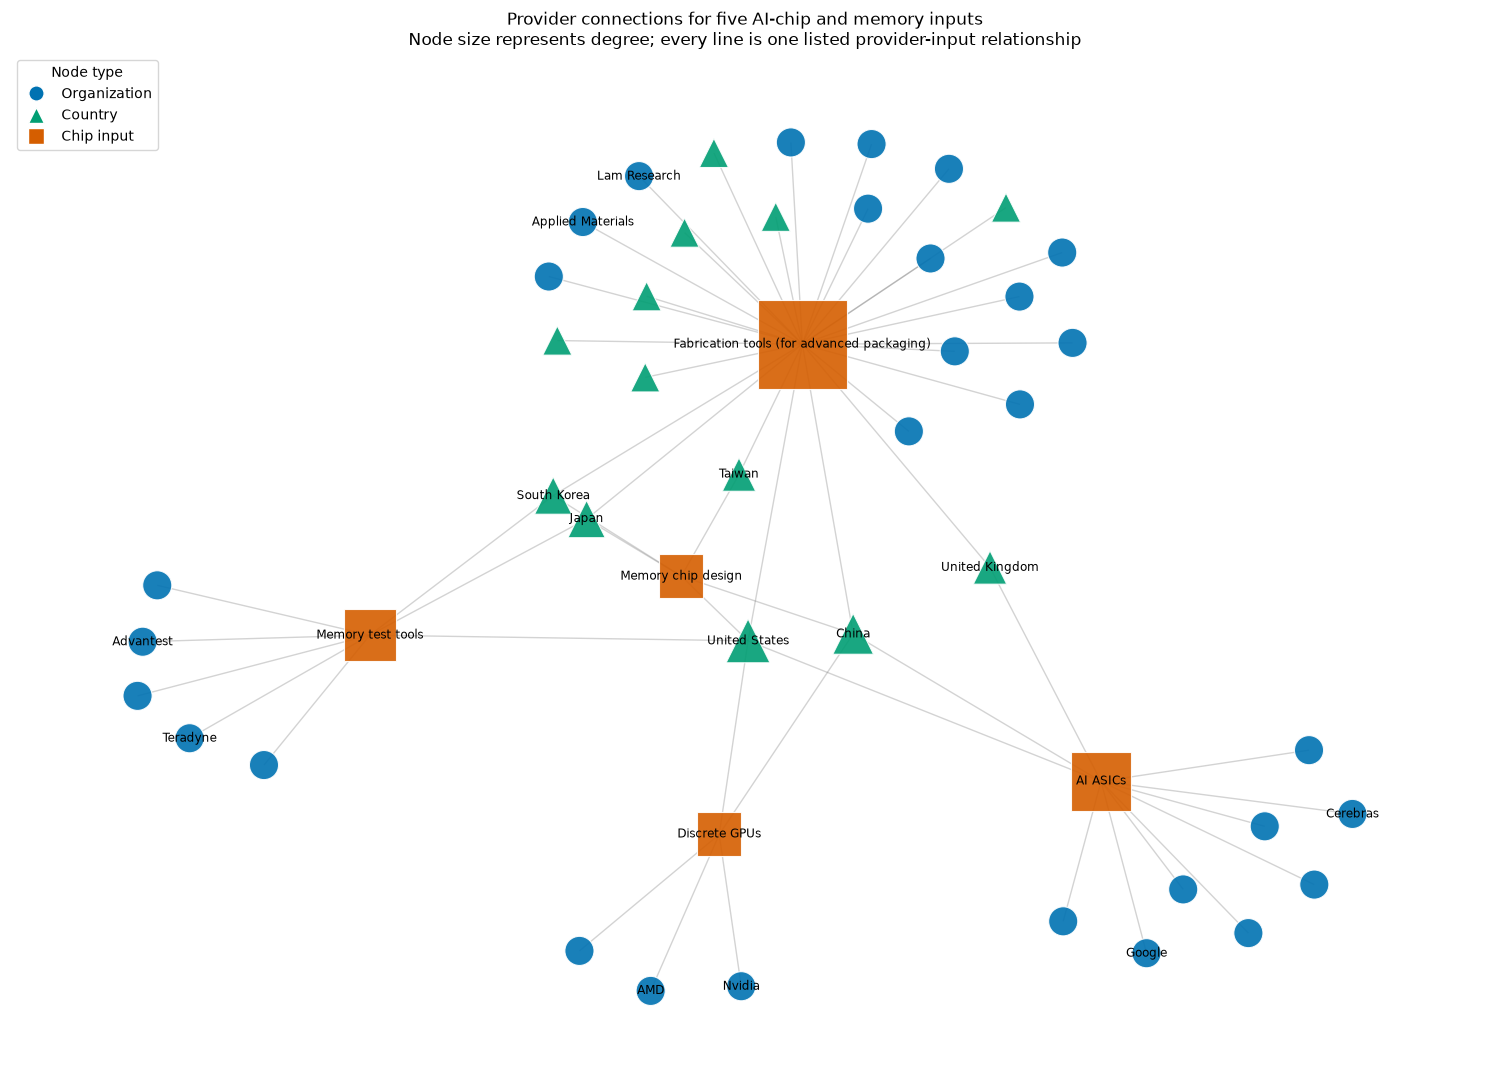

In [6]:
position = nx.spring_layout(graph, seed=SEED, k=0.65, iterations=200)
colors = {"organization": "#0072B2", "country": "#009E73", "input": "#D55E00"}
shapes = {"organization": "o", "country": "^", "input": "s"}

fig, ax = plt.subplots(figsize=(15, 11))
nx.draw_networkx_edges(graph, position, edge_color="#777777", alpha=0.32, width=1.0, ax=ax)

for node_type in ["organization", "country", "input"]:
    nodes = [n for n, d in graph.nodes(data=True) if d["node_type"] == node_type]
    nx.draw_networkx_nodes(
        graph,
        position,
        nodelist=nodes,
        node_color=colors[node_type],
        node_shape=shapes[node_type],
        node_size=[300 + 140 * graph.degree(n) for n in nodes],
        edgecolors="white",
        linewidths=0.8,
        alpha=0.9,
        ax=ax,
    )

familiar_companies = {
    "Nvidia", "AMD", "Google", "Cerebras", "Applied Materials",
    "Lam Research", "Advantest", "Teradyne",
}
labels = {
    node: data["label"]
    for node, data in graph.nodes(data=True)
    if data["node_type"] == "input" or graph.degree(node) > 1 or data["label"] in familiar_companies
}
nx.draw_networkx_labels(graph, position, labels=labels, font_size=8.5, ax=ax)

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=colors["organization"], markeredgecolor="white", markersize=11, label="Organization"),
    Line2D([0], [0], marker="^", color="none", markerfacecolor=colors["country"], markeredgecolor="white", markersize=11, label="Country"),
    Line2D([0], [0], marker="s", color="none", markerfacecolor=colors["input"], markeredgecolor="white", markersize=11, label="Chip input"),
]
ax.legend(handles=legend_handles, title="Node type", loc="upper left")
ax.set_title("Provider connections for five AI-chip and memory inputs\nNode size represents degree; every line is one listed provider-input relationship")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUTS / "focus_bipartite_network.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Project the network onto the five inputs

The projection connects two inputs when they share at least one provider. Edge weight is the number of shared providers. This smaller graph makes overlap easier to see, but it is derived from the same provider-input records.

,input_1,input_2,shared_providers
0,Fabrication tools (for advanced packaging),Memory chip design,5
2,Fabrication tools (for advanced packaging),AI ASICs,3
4,Memory test tools,Memory chip design,3
3,Fabrication tools (for advanced packaging),Memory test tools,3
1,Fabrication tools (for advanced packaging),Discrete GPUs,2
7,Memory chip design,Discrete GPUs,2
9,Discrete GPUs,AI ASICs,2
8,Memory chip design,AI ASICs,2
5,Memory test tools,AI ASICs,1
6,Memory test tools,Discrete GPUs,1


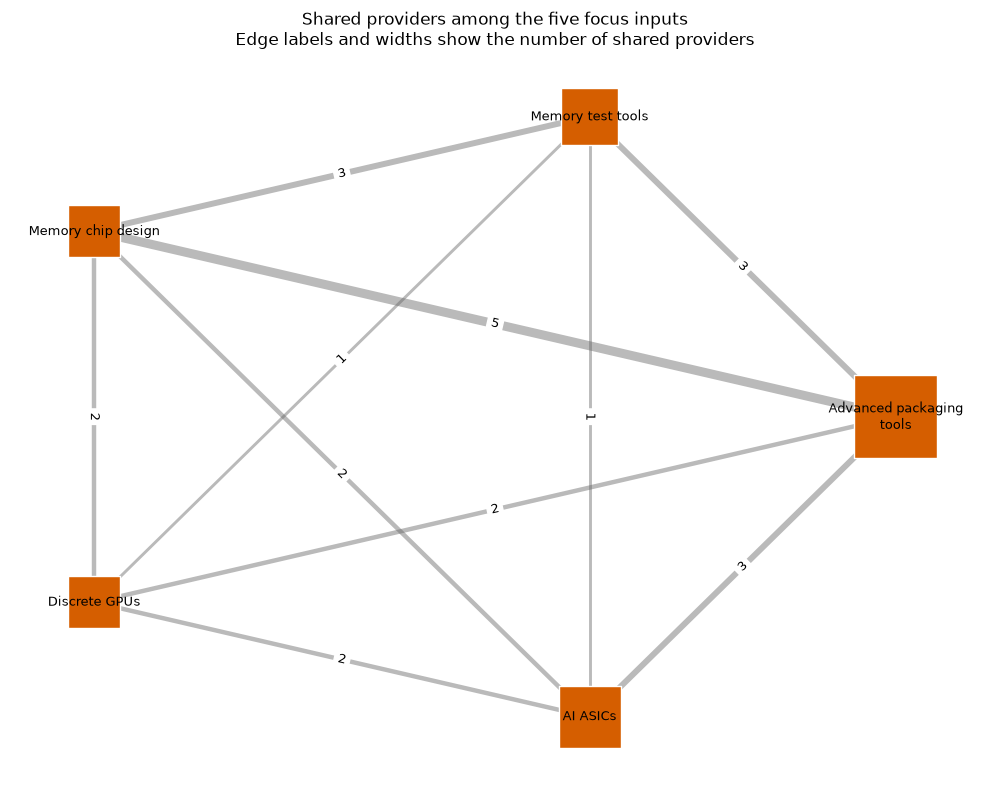

In [7]:
projection = bipartite.weighted_projected_graph(graph, input_nodes)
projection_edges = pd.DataFrame([
    {
        "input_1": graph.nodes[left]["label"],
        "input_2": graph.nodes[right]["label"],
        "shared_providers": data["weight"],
    }
    for left, right, data in projection.edges(data=True)
]).sort_values("shared_providers", ascending=False)

display(projection_edges)
projection_edges.to_csv(OUTPUTS / "input_projection_edges.csv", index=False)

projection_position = nx.circular_layout(projection)
fig, ax = plt.subplots(figsize=(10, 8))
projection_widths = [1.0 + 1.1 * projection[u][v]["weight"] for u, v in projection.edges()]
nx.draw_networkx_edges(projection, projection_position, width=projection_widths, alpha=0.45, edge_color="#666666", ax=ax)
nx.draw_networkx_nodes(
    projection,
    projection_position,
    node_color="#D55E00",
    node_shape="s",
    node_size=[900 + 100 * graph.degree(node) for node in projection.nodes()],
    edgecolors="white",
    linewidths=1,
    ax=ax,
)
projection_labels = {
    node: (
        "Advanced packaging\ntools"
        if graph.nodes[node]["label"] == "Fabrication tools (for advanced packaging)"
        else graph.nodes[node]["label"]
    )
    for node in projection.nodes()
}
nx.draw_networkx_labels(projection, projection_position, labels=projection_labels, font_size=9, ax=ax)
edge_labels = {(u, v): projection[u][v]["weight"] for u, v in projection.edges()}
nx.draw_networkx_edge_labels(projection, projection_position, edge_labels=edge_labels, font_size=9, ax=ax)
ax.set_title("Shared providers among the five focus inputs\nEdge labels and widths show the number of shared providers")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUTS / "focus_input_projection.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Examine two market-share examples

Market-share values are not available consistently across all five inputs, so they are not used as network weights. Two complete examples help explain concentration: country shares for memory-chip design and company shares for memory-testing tools. Country and company rows are kept separate because they represent different levels of analysis.

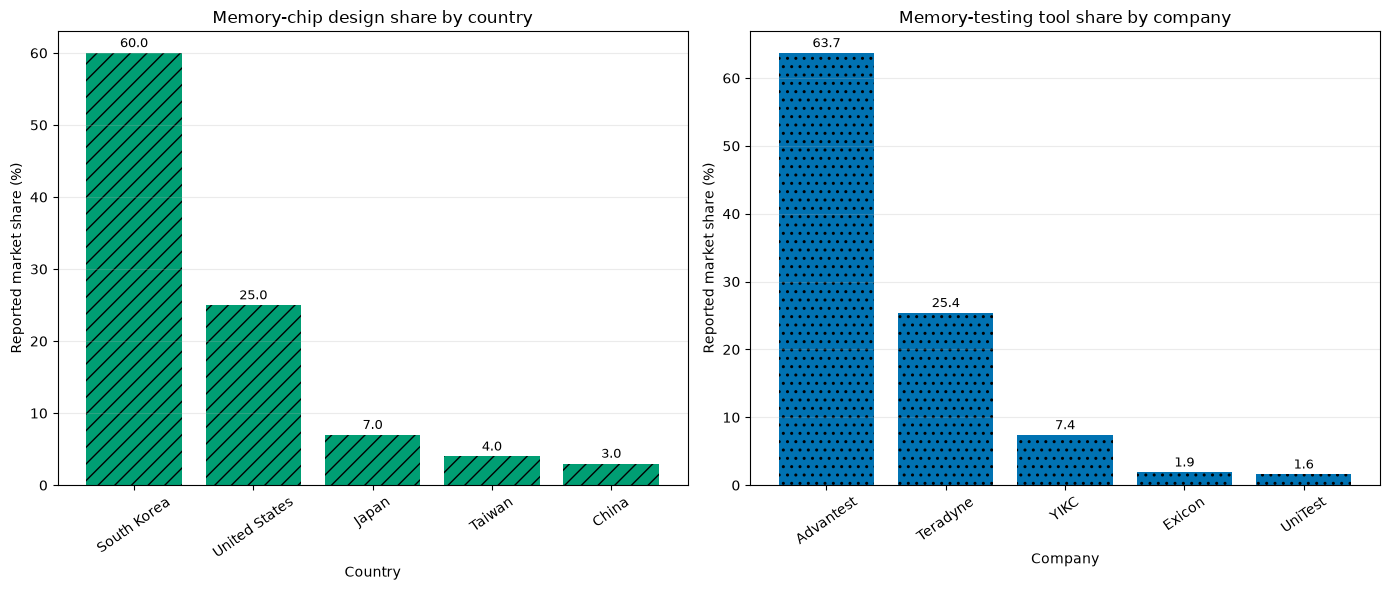

,provider_label,share_provided
41,South Korea,60.0
43,United States,25.0
40,Japan,7.0
42,Taiwan,4.0
39,China,3.0


,provider_label,share_provided
3,Advantest,63.7
29,Teradyne,25.4
38,YIKC,7.4
11,Exicon,1.9
33,UniTest,1.6


In [8]:
memory_design = (
    focus.loc[
        (focus["provided_name"] == "Memory chip design")
        & (focus["provider_type"] == "country")
        & focus["share_provided"].notna(),
        ["provider_label", "share_provided"],
    ]
    .sort_values("share_provided", ascending=False)
)

memory_test = (
    focus.loc[
        (focus["provided_name"] == "Memory test tools")
        & (focus["provider_type"] == "organization")
        & focus["share_provided"].notna(),
        ["provider_label", "share_provided"],
    ]
    .sort_values("share_provided", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(memory_design["provider_label"], memory_design["share_provided"], color="#009E73", hatch="//")
axes[0].set_title("Memory-chip design share by country")
axes[0].set_xlabel("Country")
axes[0].set_ylabel("Reported market share (%)")
axes[0].tick_params(axis="x", rotation=35)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(memory_test["provider_label"], memory_test["share_provided"], color="#0072B2", hatch="..")
axes[1].set_title("Memory-testing tool share by company")
axes[1].set_xlabel("Company")
axes[1].set_ylabel("Reported market share (%)")
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(axis="y", alpha=0.25)

for axis in axes:
    for container in axis.containers:
        axis.bar_label(container, fmt="%.1f", padding=2, fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUTS / "memory_market_share_examples.png", dpi=180, bbox_inches="tight")
plt.show()

display(memory_design)
display(memory_test)

## 9. Results and limitations

The United States is connected to all five focus inputs. China is connected to four, while Japan and South Korea are each connected to three. The organization nodes are more specialized in this subset: each named company is connected to one selected input.

Advanced-packaging tools have the widest listed provider base with 27 providers. Discrete GPUs and memory-chip design have the narrowest listed provider bases with five each. In the input projection, advanced-packaging tools and memory-chip design share five providers, the largest overlap among the selected inputs.

The market-share examples also show concentration in the reported years. South Korea accounts for 60% of the listed 2022 memory-chip design share, followed by the United States at 25%. Advantest accounts for 63.7% of the listed 2025 memory-testing tool share, followed by Teradyne at 25.4%.

These results do not establish that a shortage exists. The dataset is a high-level snapshot, not a time series. Some AI design data is from 2019 or 2022, while most equipment data uses 2025 values. Provider country represents the headquarters of the ultimate parent and not necessarily the physical production location. The source can also omit small providers or group them into aggregate categories.

In [9]:
summary = {
    "source_inputs": int(inputs["input_id"].nunique()),
    "source_unique_providers": int(providers["provider_id"].nunique()),
    "source_relationships": len(provision),
    "focus_relationships": graph.number_of_edges(),
    "focus_providers": len(provider_nodes),
    "focus_inputs": len(input_nodes),
    "focus_nodes": graph.number_of_nodes(),
    "top_provider": provider_metrics.iloc[0]["provider"],
    "top_provider_degree": int(provider_metrics.iloc[0]["focus_input_degree"]),
    "fewest_provider_count": int(input_metrics["listed_provider_degree"].min()),
    "widest_provider_count": int(input_metrics["listed_provider_degree"].max()),
}
summary

{'source_inputs': 126,
 'source_unique_providers': 396,
 'source_relationships': 1300,
 'focus_relationships': 56,
 'focus_providers': 43,
 'focus_inputs': 5,
 'focus_nodes': 48,
 'top_provider': 'United States',
 'top_provider_degree': 5,
 'fewest_provider_count': 5,
 'widest_provider_count': 27}

## 10. References and learning resources

### Sources used for data, context, and method

1. Emerging Technology Observatory. (2026). *Semiconductor Supply Chain Dataset: documentation for the September 2026 release.* https://www.eto.tech/dataset-docs/chipexplorer/index.html
2. Center for Security and Emerging Technology. (2026). *ETO Semiconductor Supply Chain Dataset repository.* https://github.com/georgetown-cset/eto-chip-explorer/tree/main/data
3. Khan, S. M., Mann, A., & Peterson, D. (2021). *The semiconductor supply chain: Assessing national competitiveness.* https://doi.org/10.51593/20190016
4. NetworkX Developers. (2026). *NetworkX tutorial.* https://networkx.org/documentation/stable/tutorial.html
5. NetworkX Developers. (2026). *Bipartite algorithms.* https://networkx.org/documentation/stable/reference/algorithms/bipartite.html
6. pandas development team. (2026). *pandas documentation.* https://pandas.pydata.org/docs/
7. Matplotlib development team. (2026). *Matplotlib documentation.* https://matplotlib.org/stable/

### Optional learning support

- W3Schools, *Pandas Tutorial*: https://www.w3schools.com/python/pandas/default.asp
- Codecademy, *Learn Data Analysis with Pandas*: https://www.codecademy.com/learn/data-processing-pandas
- Eric Ma, *Network Analysis Made Simple* (PyCon US video): https://www.youtube.com/watch?v=5vU5nRjaac4
- Eric Ma and Mridul Seth, *Network Analysis Made Simple* (SciPy video): https://www.youtube.com/watch?v=LTnsaD-rXW4
- Albert-Laszlo Barabasi, *Network Science*: https://www.networksciencebook.com/
- Michele Coscia, *The Atlas for the Aspiring Network Scientist* (free PDF): https://arxiv.org/pdf/2101.00863

The complete annotated list, including additional PDFs and exact usage notes, is in `04_Resources/REFERENCES.md`. Tutorial sites and videos are learning aids; the project findings come from the saved ETO tables and executed code.